# HW2 Starter：CNN 醫學影像分類

**對應單元**：W6 CNN / 遷移學習　|　**環境**：Google Colab（建議開 T4 GPU）

> 這是骨架，填完每個 `# TODO` 即可。刻意設計成 Colab 免費層可跑完：小圖、小模型、少 epoch。

## 環境設定

In [1]:
!pip install -q "medmnist>=3.0"
import torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt
import torch.nn.functional as F
import pandas as pd
from medmnist import PneumoniaMNIST, INFO
dev = 'cuda' if torch.cuda.is_available() else 'cpu'; print('device:', dev)
# 沿用 HW1：from mypreproc import normalize   # 上傳 mypreproc.py 後 import
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/medimg_toolkit')
from mypreproc import normalize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 8.3 MB/s eta 0:00:00
device: cuda
Mounted at /content/drive


## B1 載入與檢視
載入資料、印筆數/類別分布、顯示每類範例。

100%|██████████| 4.17M/4.17M [00:01<00:00, 3.90MB/s]


,Split,Total,Shape,Dtype,Min~Max,Normal (0),Pneumonia (1),Ratio (1:0)
0,Train,4708,"(28, 28)",uint8,0 ~ 255,1214 (25.8%),3494 (74.2%),2.88 : 1
1,Val,524,"(28, 28)",uint8,0 ~ 255,135 (25.8%),389 (74.2%),2.88 : 1
2,Test,624,"(28, 28)",uint8,0 ~ 254,234 (37.5%),390 (62.5%),1.67 : 1


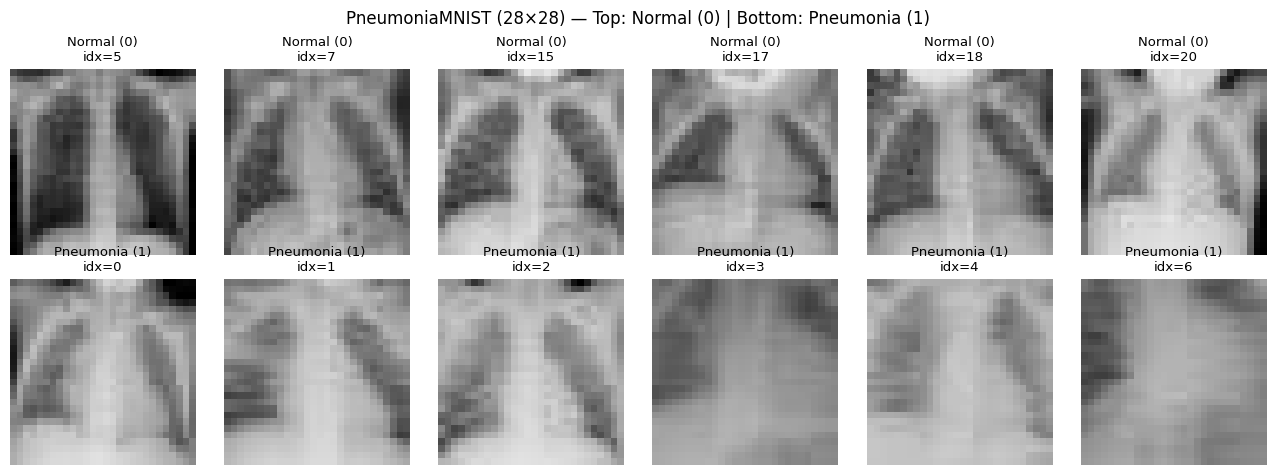

In [2]:
train = PneumoniaMNIST(split='train', download=True, size=28)
val   = PneumoniaMNIST(split='val',   download=True, size=28)
test  = PneumoniaMNIST(split='test',  download=True, size=28)
# TODO: 印出 train/val/test 筆數、影像 shape、類別分布（是否不平衡？）
# TODO: 每類顯示幾張範例圖

# 印出資料集筆數、shape、dtype、像素範圍與類別分布
rows_b1 = []
for split_name, ds in [("Train", train), ("Val", val), ("Test", test)]:
    imgs = ds.imgs
    labs = ds.labels.ravel()
    n0 = int((labs == 0).sum())
    n1 = int((labs == 1).sum())
    rows_b1.append({
        "Split": split_name,
        "Total": len(imgs),
        "Shape": str(imgs[0].shape),
        "Dtype": str(imgs.dtype),
        "Min~Max": f"{imgs.min()} ~ {imgs.max()}",
        "Normal (0)": f"{n0} ({n0/len(labs)*100:.1f}%)",
        "Pneumonia (1)": f"{n1} ({n1/len(labs)*100:.1f}%)",
        "Ratio (1:0)": f"{n1/n0:.2f} : 1"
    })

df_b1 = pd.DataFrame(rows_b1)
display(df_b1)

# 顯示每類 6 張範例影像
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
tr_labs = train.labels.ravel()
norm_idx = np.where(tr_labs == 0)[0][:6]
pneu_idx = np.where(tr_labs == 1)[0][:6]

for j, idx_s in enumerate(norm_idx):
    axes[0, j].imshow(train.imgs[idx_s], cmap='gray', vmin=0, vmax=255)
    axes[0, j].set_title(f"Normal (0)\nidx={idx_s}", fontsize=9.5)
    axes[0, j].axis('off')

for j, idx_s in enumerate(pneu_idx):
    axes[1, j].imshow(train.imgs[idx_s], cmap='gray', vmin=0, vmax=255)
    axes[1, j].set_title(f"Pneumonia (1)\nidx={idx_s}", fontsize=9.5)
    axes[1, j].axis('off')

plt.suptitle("PneumoniaMNIST (28×28) — Top: Normal (0) | Bottom: Pneumonia (1)", fontsize=12)
plt.tight_layout()
plt.show()

Train / Val / Test 筆數分別為 4,708、524、624 張，影像尺寸皆為 `(28, 28)`，資料型態為 `uint8`（像素值範圍 `0 ~ 255`）。資料集呈現明顯的類別不平衡（Class Imbalance）：`Normal (0)` 為少數類（在 Train 與 Val 僅占約 25.8%，在 Test 占 37.5%），`Pneumonia (1)` 為多數類（在 Train 與 Val 占約 74.2%，在 Test 占 62.5%）。

## B2 前處理與 DataLoader
normalization + augmentation + DataLoader。

batch x shape: torch.Size([64, 1, 28, 28]) | dtype: torch.float32 | range: [0.000, 1.000]
batch y shape: torch.Size([64]) | dtype: torch.int64


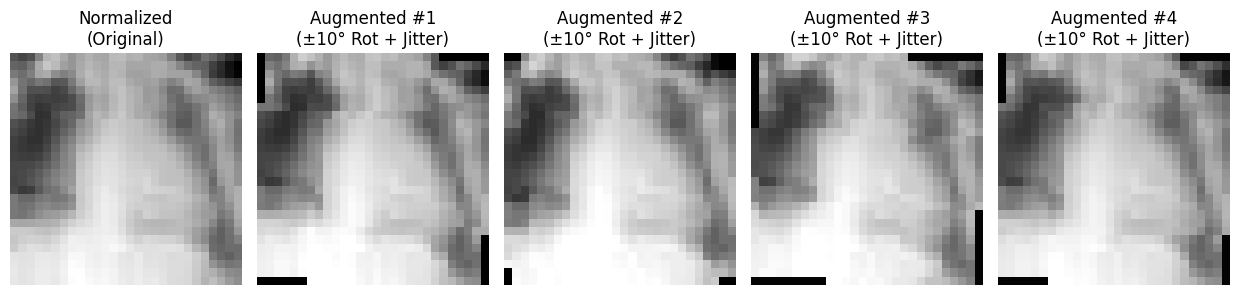

In [3]:
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset, Dataset
# TODO: 用 HW1 mypreproc 或這裡做 normalize；加 augmentation：小角度旋轉、亮度擾動；不可上下翻轉（10/12 augmentation 頁）
# 提示：transform 可直接傳給 PneumoniaMNIST(split=..., transform=..., download=True, size=28)
# 提示：labels 形狀是 (N,1)，送進 CrossEntropyLoss 前要 y.squeeze().long()
# TODO: 建 train/val/test DataLoader（batch_size 如 64）

# 訓練集 Augmentation：小角度旋轉 (±10°) + 亮度/對比微幅擾動 (±10%)，不可上下翻轉
train_aug = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
])

class ChestXRayDataset(Dataset):
    def __init__(self, medmnist_ds, is_train=False):
        self.imgs = medmnist_ds.imgs
        self.labels = medmnist_ds.labels.squeeze().astype(np.int64)
        self.is_train = is_train

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # 使用 HW1 mypreproc.normalize 正規化至 [0, 1]
        img_norm = normalize(self.imgs[idx], mode='minmax').astype(np.float32)
        x = torch.from_numpy(img_norm).unsqueeze(0)  # (1, 28, 28)
        if self.is_train:
            x = torch.clamp(train_aug(x), 0.0, 1.0)
        y = torch.tensor(self.labels[idx], dtype=torch.long)
        return x, y

train_ds = ChestXRayDataset(train, is_train=True)
val_ds   = ChestXRayDataset(val,   is_train=False)
test_ds  = ChestXRayDataset(test,  is_train=False)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

xb, yb = next(iter(train_loader))
print("batch x shape:", xb.shape, "| dtype:", xb.dtype, f"| range: [{xb.min():.3f}, {xb.max():.3f}]")
print("batch y shape:", yb.shape, "| dtype:", yb.dtype)

# 顯示正規化原圖與 4 張隨機 Augmentation 結果
fig, axes = plt.subplots(1, 5, figsize=(12.5, 2.9))
sample_raw, _ = val_ds[0]
axes[0].imshow(sample_raw.squeeze(0).numpy(), cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Normalized\n(Original)")
axes[0].axis('off')

for k in range(1, 5):
    aug_sample = torch.clamp(train_aug(sample_raw), 0.0, 1.0)
    axes[k].imshow(aug_sample.squeeze(0).numpy(), cmap='gray', vmin=0, vmax=1)
    axes[k].set_title(f"Augmented #{k}\n(±10° Rot + Jitter)")
    axes[k].axis('off')

plt.tight_layout()
plt.show()

透過 HW1 的 `mypreproc.normalize` 將像素值正規化至 `0.0 ~ 1.0` 後，對訓練集加入 ±10° 小角度旋轉與 ±10% 亮度/對比微擾，可模擬拍攝時病患微幅傾斜與不同 X 光機曝光差異（彌補卷積對旋轉的不敏感，見 10/12 投影片 Slide 14）。胸部 X 光具有固定解剖方向（肺尖在上、橫膈膜在下、心影偏左），上下翻轉會產生解剖上不可能存在的倒置胸腔（Slide 28），左右翻轉則會造成人工右位心，因此關閉翻轉操作。

## B3 小 CNN
2-3 個卷積區塊 + GAP + 線性頭，參數 < 1M。

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, in_channels=1, n_cls=2):
        super().__init__()
        # TODO: 卷積區塊(Conv-BN-ReLU-Pool) x2~3 -> AdaptiveAvgPool2d(1) -> Linear
        # 設計 3 個卷積區塊（通道數 1 -> 16 -> 32 -> 64，與 10/12 投影片 Slide 22 的 2 區塊範例不同）
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, n_cls)

    def features(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return x

    def forward(self, x):
        # TODO
        x = self.features(x)
        x = self.gap(x).flatten(1)
        return self.fc(x)

model = SmallCNN().to(dev)
print('params:', sum(p.numel() for p in model.parameters()))

# 逐層核對公式計算之 Output Shape 與參數量
dummy = torch.zeros(4, 1, 28, 28, device=dev)
with torch.no_grad():
    o1_conv = model.block1[0](dummy)
    o1_bn   = model.block1[1](o1_conv)
    o1_out  = model.block1(dummy)
    o2_conv = model.block2[0](o1_out)
    o2_bn   = model.block2[1](o2_conv)
    o2_out  = model.block2(o1_out)
    o3_conv = model.block3[0](o2_out)
    o3_out  = model.block3(o2_out)
    o_gap   = model.gap(o3_out).flatten(1)
    o_fc    = model(dummy)

df_b3 = pd.DataFrame([
    {"Layer": "Input",                          "Formula Output Shape": "(B, 1, 28, 28)",  "Actual Shape": str(tuple(dummy.shape)),   "Formula Params": 0},
    {"Layer": "Block1: Conv2d(1->16, 3x3, p=1)","Formula Output Shape": "(B, 16, 28, 28)", "Actual Shape": str(tuple(o1_conv.shape)), "Formula Params": (1*3*3+1)*16},
    {"Layer": "Block1: BatchNorm2d(16)",        "Formula Output Shape": "(B, 16, 28, 28)", "Actual Shape": str(tuple(o1_bn.shape)),   "Formula Params": 2*16},
    {"Layer": "Block1: ReLU + MaxPool2d(2x2)",  "Formula Output Shape": "(B, 16, 14, 14)", "Actual Shape": str(tuple(o1_out.shape)),  "Formula Params": 0},
    {"Layer": "Block2: Conv2d(16->32, 3x3,p=1)","Formula Output Shape": "(B, 32, 14, 14)", "Actual Shape": str(tuple(o2_conv.shape)), "Formula Params": (16*3*3+1)*32},
    {"Layer": "Block2: BatchNorm2d(32)",        "Formula Output Shape": "(B, 32, 14, 14)", "Actual Shape": str(tuple(o2_bn.shape)),   "Formula Params": 2*32},
    {"Layer": "Block2: ReLU + MaxPool2d(2x2)",  "Formula Output Shape": "(B, 32, 7, 7)",   "Actual Shape": str(tuple(o2_out.shape)),  "Formula Params": 0},
    {"Layer": "Block3: Conv2d(32->64, 3x3,p=1)","Formula Output Shape": "(B, 64, 7, 7)",   "Actual Shape": str(tuple(o3_conv.shape)), "Formula Params": (32*3*3+1)*64},
    {"Layer": "Block3: BatchNorm2d(64) + ReLU", "Formula Output Shape": "(B, 64, 7, 7)",   "Actual Shape": str(tuple(o3_out.shape)),  "Formula Params": 2*64},
    {"Layer": "GAP: AdaptiveAvgPool2d(1)",      "Formula Output Shape": "(B, 64)",         "Actual Shape": str(tuple(o_gap.shape)),   "Formula Params": 0},
    {"Layer": "Linear(64 -> 2)",                "Formula Output Shape": "(B, 2)",          "Actual Shape": str(tuple(o_fc.shape)),    "Formula Params": (64+1)*2},
])
display(df_b3)
print("Formula Total Params:", df_b3["Formula Params"].sum(), "| PyTorch Params:", sum(p.numel() for p in model.parameters()))

params: 23650


,Layer,Formula Output Shape,Actual Shape,Formula Params
0,Input,"(B, 1, 28, 28)","(4, 1, 28, 28)",0
1,"Block1: Conv2d(1->16, 3x3, p=1)","(B, 16, 28, 28)","(4, 16, 28, 28)",160
2,Block1: BatchNorm2d(16),"(B, 16, 28, 28)","(4, 16, 28, 28)",32
3,Block1: ReLU + MaxPool2d(2x2),"(B, 16, 14, 14)","(4, 16, 14, 14)",0
4,"Block2: Conv2d(16->32, 3x3,p=1)","(B, 32, 14, 14)","(4, 32, 14, 14)",4640
5,Block2: BatchNorm2d(32),"(B, 32, 14, 14)","(4, 32, 14, 14)",64
6,Block2: ReLU + MaxPool2d(2x2),"(B, 32, 7, 7)","(4, 32, 7, 7)",0
7,"Block3: Conv2d(32->64, 3x3,p=1)","(B, 64, 7, 7)","(4, 64, 7, 7)",18496
8,Block3: BatchNorm2d(64) + ReLU,"(B, 64, 7, 7)","(4, 64, 7, 7)",128
9,GAP: AdaptiveAvgPool2d(1),"(B, 64)","(4, 64)",0


Formula Total Params: 23650 | PyTorch Params: 23650


`SmallCNN` 設計為 3 個 `3×3` 卷積區塊（通道數 `1 → 16 → 32 → 64`，不同於 10/12 投影片 Slide 22 範例的 2 個區塊 `1 → 16 → 32`），經兩次 `2×2` MaxPooling 將空間尺寸由 `28×28` 縮小至 `7×7`，再透過 Global Average Pooling 將每個通道平均為 1 個數值並接 `Linear(64, 2)`。以公式 $(F^2 C_{\text{in}} + 1)C_{\text{out}}$ 與 BN 參數 $2C_{\text{out}}$ 計算之總參數量為 `23,650`，與 `model.parameters()` 核對完全一致，且遠小於 1M 上限。

## B4 訓練
交叉熵 + Adam，≤10 epoch，畫 loss/acc 曲線。

Epoch 01/10 | Train Loss: 0.3074 Acc: 0.9034 | Val Loss: 0.2118 Acc: 0.9103 AUROC: 0.9727
Epoch 02/10 | Train Loss: 0.1793 Acc: 0.9308 | Val Loss: 0.2258 Acc: 0.8989 AUROC: 0.9855
Epoch 03/10 | Train Loss: 0.1531 Acc: 0.9414 | Val Loss: 0.1309 Acc: 0.9561 AUROC: 0.9910
Epoch 04/10 | Train Loss: 0.1417 Acc: 0.9465 | Val Loss: 0.2630 Acc: 0.9046 AUROC: 0.9838
Epoch 05/10 | Train Loss: 0.1329 Acc: 0.9490 | Val Loss: 0.2840 Acc: 0.8817 AUROC: 0.9801
Epoch 06/10 | Train Loss: 0.1166 Acc: 0.9558 | Val Loss: 0.4511 Acc: 0.8321 AUROC: 0.9926
Epoch 07/10 | Train Loss: 0.1073 Acc: 0.9579 | Val Loss: 0.1470 Acc: 0.9389 AUROC: 0.9921
Epoch 08/10 | Train Loss: 0.1096 Acc: 0.9588 | Val Loss: 0.3680 Acc: 0.8702 AUROC: 0.9946
Epoch 09/10 | Train Loss: 0.1041 Acc: 0.9596 | Val Loss: 0.1912 Acc: 0.9179 AUROC: 0.9952
Epoch 10/10 | Train Loss: 0.1062 Acc: 0.9582 | Val Loss: 0.8011 Acc: 0.8053 AUROC: 0.9826


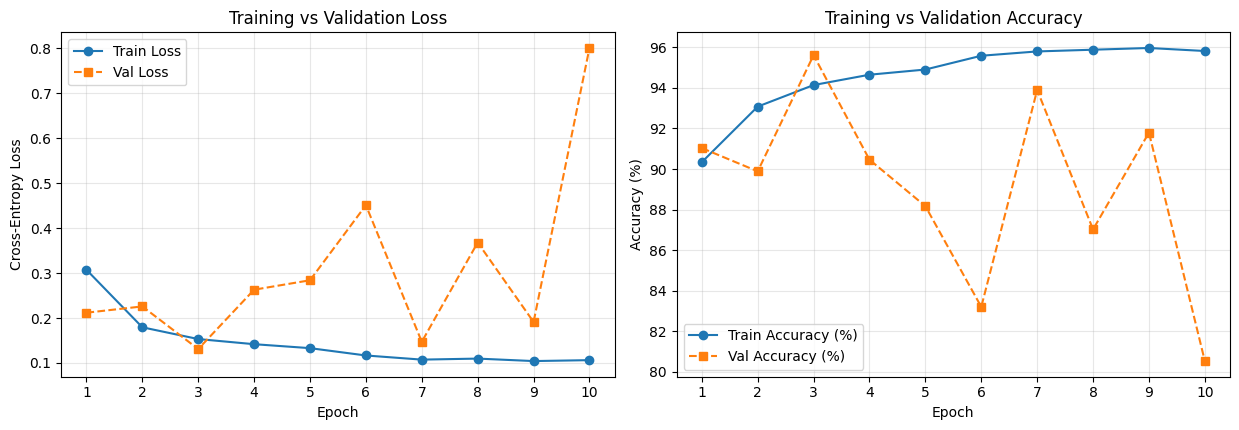

In [5]:
import copy

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()
# TODO: 訓練迴圈（≤10 epoch），記錄 train/val loss 與 accuracy
# TODO: 畫曲線；觀察 val 是否回升（過擬合）

def evaluate_loader(net, loader):
    net.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(dev), yb.to(dev)
            logits = net(xb)
            loss = crit(logits, yb)
            probs = torch.softmax(logits, dim=1)[:, 1]
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(yb.cpu().numpy())
    probs_np = np.concatenate(all_probs)
    labels_np = np.concatenate(all_labels)
    pos = probs_np[labels_np == 1]
    neg = probs_np[labels_np == 0]
    diff = pos[:, None] - neg[None, :]
    auc_val = float((np.sum(diff > 0) + 0.5 * np.sum(diff == 0)) / (len(pos) * len(neg)))
    return total_loss / total, correct / total, auc_val, probs_np, labels_np

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_auroc': []}
best_val_loss = float('inf')
best_state = None

for epoch in range(1, 11):
    model.train()
    tr_loss_sum, tr_corr, tr_tot = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(dev), yb.to(dev)
        opt.zero_grad()
        logits = model(xb)
        loss = crit(logits, yb)
        loss.backward()
        opt.step()
        tr_loss_sum += loss.item() * len(yb)
        tr_corr += (logits.argmax(dim=1) == yb).sum().item()
        tr_tot += len(yb)

    tr_loss = tr_loss_sum / tr_tot
    tr_acc  = tr_corr / tr_tot
    val_loss, val_acc, val_auc, _, _ = evaluate_loader(model, val_loader)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(val_acc)
    history['val_auroc'].append(val_auc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch:02d}/10 | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} AUROC: {val_auc:.4f}")

# 載回驗證集最佳權重並存檔到 Drive（HW5 要載回）
model.load_state_dict(best_state)
torch.save(model.state_dict(), '/content/drive/MyDrive/medimg_toolkit/hw2_cnn.pt')

# 繪製 Train / Val Loss 與 Accuracy 曲線
epochs_arr = np.arange(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))

ax[0].plot(epochs_arr, history['train_loss'], 'o-', label='Train Loss')
ax[0].plot(epochs_arr, history['val_loss'], 's--', label='Val Loss')
ax[0].set_title("Training vs Validation Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Cross-Entropy Loss")
ax[0].set_xticks(epochs_arr)
ax[0].grid(True, alpha=0.3)
ax[0].legend()

ax[1].plot(epochs_arr, np.array(history['train_acc']) * 100, 'o-', label='Train Accuracy (%)')
ax[1].plot(epochs_arr, np.array(history['val_acc']) * 100, 's--', label='Val Accuracy (%)')
ax[1].set_title("Training vs Validation Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy (%)")
ax[1].set_xticks(epochs_arr)
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

訓練過程中 Train Loss 由 0.3074 持續下降至 0.1041～0.1062（Train Accuracy 提升至 95.96%），而 Val Loss 在 Epoch 3 達到最低點 0.1309（Val Accuracy = 95.61%、Val AUROC = 0.9910）後，於後續 Epoch 出現明顯震盪與回升（如 Epoch 6 升至 0.4511、Epoch 10 升至 0.8011）。此「訓練損失持續下降、驗證損失反轉回升（train-val gap 擴大）」即為典型的過擬合現象。

## B5 誠實評估
AUROC + 混淆矩陣 + P/R/F1。把 AUROC 寫進 mymetrics.py。

mymetrics.auroc: 0.929608 | sklearn roc_auc_score: 0.929608 | diff: 0.00e+00


,Majority Baseline Acc,Test Accuracy,Test AUROC,Precision,Recall (Sensitivity),Specificity,F1-score,TN / FP / FN / TP
0,62.50%,84.46%,0.9296,0.8137,0.9744,0.6282,0.8868,147 / 87 / 10 / 380


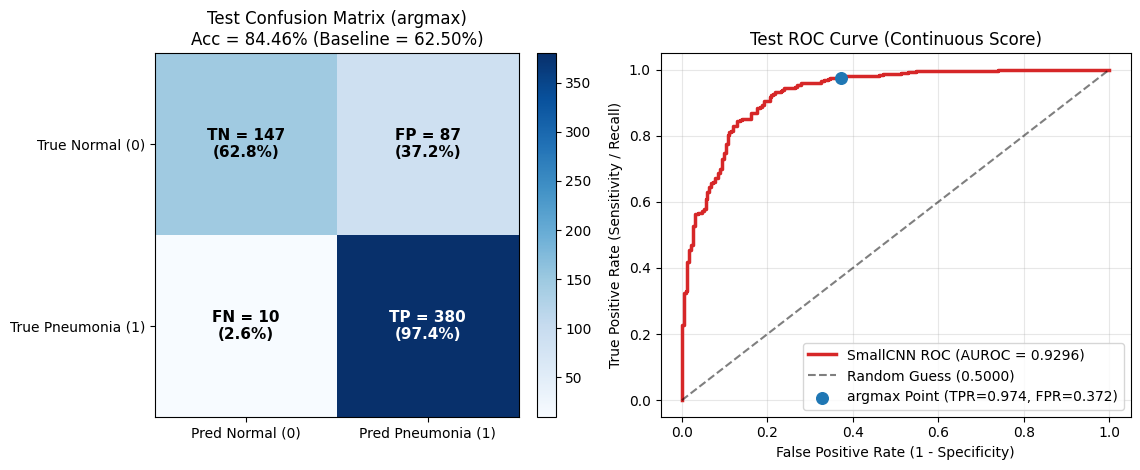

In [6]:
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, roc_curve
# TODO: 在 test 上收集機率與標籤，算 AUROC、混淆矩陣、precision/recall/F1
# TODO: 畫混淆矩陣；比較 accuracy vs AUROC 說的故事是否一致

# 實作 AUROC（依 A5 陽性分數 > 陰性分數的配對比例計算，後續於打包工具庫格寫入 mymetrics.py）
def auroc(y_true, score):
    y_true = np.asarray(y_true).ravel()
    score = np.asarray(score, dtype=np.float64).ravel()
    pos = score[y_true == 1]
    neg = score[y_true == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    diff = pos[:, None] - neg[None, :]
    concordant = np.sum(diff > 0) + 0.5 * np.sum(diff == 0)
    return float(concordant / (len(pos) * len(neg)))

_, test_acc, _, test_probs, y_test = evaluate_loader(model, test_loader)
test_preds = (test_probs >= 0.5).astype(np.int64)  # 門檻為 argmax (p >= 0.5)

my_auc = auroc(y_test, test_probs)
sk_auc = float(roc_auc_score(y_test, test_probs))

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()
prec = tp / (tp + fp)
rec  = tp / (tp + fn)
spec = tn / (tn + fp)
f1   = 2 * prec * rec / (prec + rec)
maj_baseline = float((y_test == 1).mean())

print(f"mymetrics.auroc: {my_auc:.6f} | sklearn roc_auc_score: {sk_auc:.6f} | diff: {abs(my_auc - sk_auc):.2e}")
df_b5 = pd.DataFrame([{
    "Majority Baseline Acc": f"{maj_baseline*100:.2f}%",
    "Test Accuracy": f"{test_acc*100:.2f}%",
    "Test AUROC": round(my_auc, 4),
    "Precision": round(prec, 4),
    "Recall (Sensitivity)": round(rec, 4),
    "Specificity": round(spec, 4),
    "F1-score": round(f1, 4),
    "TN / FP / FN / TP": f"{tn} / {fp} / {fn} / {tp}"
}])
display(df_b5)

# 繪製混淆矩陣與 ROC 曲線
fpr, tpr, _ = roc_curve(y_test, test_probs)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

im = ax[0].imshow(cm, cmap='Blues')
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(['Pred Normal (0)', 'Pred Pneumonia (1)'])
ax[0].set_yticklabels(['True Normal (0)', 'True Pneumonia (1)'])
ax[0].set_title(f"Test Confusion Matrix (argmax)\nAcc = {test_acc*100:.2f}% (Baseline = {maj_baseline*100:.2f}%)")
labels_cm = [['TN', 'FP'], ['FN', 'TP']]
for r in range(2):
    for c in range(2):
        val = cm[r, c]
        color_txt = 'white' if val > 200 else 'black'
        ax[0].text(c, r, f"{labels_cm[r][c]} = {val}\n({val/cm[r].sum()*100:.1f}%)",
                   ha='center', va='center', color=color_txt, fontsize=11, fontweight='bold')
plt.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)

ax[1].plot(fpr, tpr, color='#d62728', lw=2.5, label=f'SmallCNN ROC (AUROC = {my_auc:.4f})')
ax[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (0.5000)')
ax[1].scatter([1 - spec], [rec], color='#1f77b4', s=70, zorder=5, label=f'argmax Point (TPR={rec:.3f}, FPR={1-spec:.3f})')
ax[1].set_title("Test ROC Curve (Continuous Score)")
ax[1].set_xlabel("False Positive Rate (1 - Specificity)")
ax[1].set_ylabel("True Positive Rate (Sensitivity / Recall)")
ax[1].grid(True, alpha=0.3)
ax[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

Accuracy 與 AUROC 說的故事並不一樣。測試集中若全部猜多數類 Pneumonia (1)，Baseline Accuracy 就已達 62.50%；且因訓練集陽性比例（74.2%）高於測試集（62.5%），模型在預設 argmax（p >= 0.5）門檻下傾向預測為陽性，使 Recall（Sensitivity）高達 97.44%（TP = 380 / 390、FN = 10），但 Specificity 較低（62.82%，TN = 147 / 234、FP = 87），整體 Accuracy 為 84.46%、Precision 為 0.8137、F1-score 為 0.8868。然而跨門檻的連續分數 AUROC 高達 0.9296（0.929608，與 sklearn 結果完全一致，diff = 0.00e+00），證明模型對正常與肺炎胸片具備良好的排序鑑別力，FP 偏高主要是決策門檻未隨測試集類別比例調整所致。

## B6 CAM
2-3 張測試圖畫 CAM 疊圖（W6 的類別活化圖；你的 SmallCNN 是 GAP+線性頭，直接適用）。

Test #0 | logit_c=+1.89623, A.mean@w_c+b_c=+1.89623, |diff|=1.19e-07 | CAM vs Grad-CAM MAE=4.26e-08
Test #2 | logit_c=+1.53737, A.mean@w_c+b_c=+1.53737, |diff|=0.00e+00 | CAM vs Grad-CAM MAE=1.80e-08
Test #3 | logit_c=+2.25306, A.mean@w_c+b_c=+2.25306, |diff|=0.00e+00 | CAM vs Grad-CAM MAE=2.73e-08


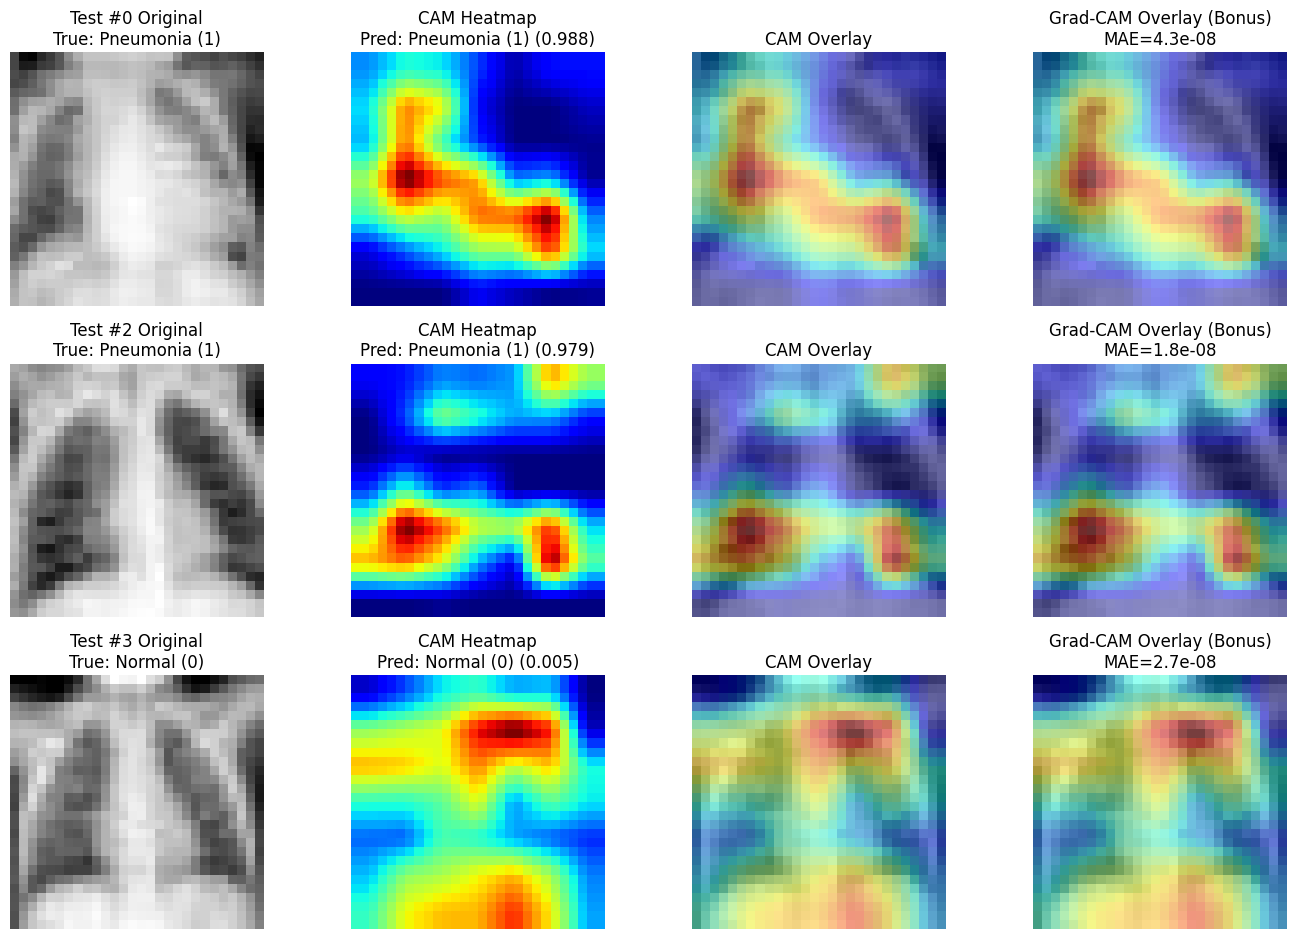

In [7]:
# CAM（GAP+線性頭專用，比 Grad-CAM 簡單）：
#   1. 取「送進 GAP 的那個張量」A (shape [C,h,w])：最後一個卷積區塊的輸出（Conv-BN-ReLU-Pool 的話是 Pool 之後）。可對 GAP 層掛 forward hook，取它的 input[0]
#      自我檢查：A.mean((1,2)) @ w_c + b_c 應等於模型輸出的 logit_c
#   2. 取分類頭 Linear 對「預測類別 c」那一列權重 w_c (shape [C])
#   3. CAM = ReLU( sum_k w_c[k] * A[k] )，上採樣回原圖大小、正規化到 [0,1]、疊圖
# TODO: 依上面三步實作 CAM，對 2-3 張測試圖畫疊圖
# 觀察：模型看的是病灶還是別處？（連 10/12 CAM 頁）
# 進階(加分)：改用 Grad-CAM（用梯度加權，11/23 那講）比較兩者差異

model.eval()
hook_cache = {}
def gap_input_hook(module, inputs, output):
    hook_cache['A'] = inputs[0]

hook_handle = model.gap.register_forward_hook(gap_input_hook)

cam_idxs = [0, 2, 3]
cls_names = {0: 'Normal (0)', 1: 'Pneumonia (1)'}
fig, axes = plt.subplots(3, 4, figsize=(14, 9.5))

for i, idx_s in enumerate(cam_idxs):
    x_img, y_true = test_ds[idx_s]
    x_in = x_img.unsqueeze(0).to(dev).requires_grad_(True)

    logits = model(x_in)
    A = hook_cache['A']  # (1, 64, 7, 7)
    A.retain_grad()

    pred_c = int(logits.argmax(dim=1).item())
    logit_c = logits[0, pred_c]
    prob_pneu = float(torch.softmax(logits, dim=1)[0, 1].item())

    # 自我檢查：A.mean((1,2)) @ w_c + b_c 應等於模型輸出的 logit_c
    w_c = model.fc.weight[pred_c]
    b_c = model.fc.bias[pred_c]
    A_single = A[0]
    reconstructed_logit = float((A_single.mean(dim=(1, 2)) @ w_c + b_c).item())
    diff_logit = abs(float(logit_c.item()) - reconstructed_logit)

    # 標準 CAM
    cam_7 = F.relu((A_single * w_c.view(-1, 1, 1)).sum(dim=0))
    cam_28 = F.interpolate(cam_7.unsqueeze(0).unsqueeze(0), size=(28, 28), mode='bilinear', align_corners=False).squeeze()
    cam_28 = (cam_28 - cam_28.min()) / (cam_28.max() - cam_28.min() + 1e-8)
    cam_np = cam_28.detach().cpu().numpy()

    # 進階(加分)：Grad-CAM
    model.zero_grad()
    logit_c.backward()
    alpha_k = A.grad[0].mean(dim=(1, 2))
    gradcam_7 = F.relu((A_single.detach() * alpha_k.view(-1, 1, 1)).sum(dim=0))
    gradcam_28 = F.interpolate(gradcam_7.unsqueeze(0).unsqueeze(0), size=(28, 28), mode='bilinear', align_corners=False).squeeze()
    gradcam_28 = (gradcam_28 - gradcam_28.min()) / (gradcam_28.max() - gradcam_28.min() + 1e-8)
    gradcam_np = gradcam_28.cpu().numpy()

    cam_gradcam_mae = float(np.abs(cam_np - gradcam_np).mean())
    print(f"Test #{idx_s} | logit_c={logit_c.item():+.5f}, A.mean@w_c+b_c={reconstructed_logit:+.5f}, |diff|={diff_logit:.2e} | CAM vs Grad-CAM MAE={cam_gradcam_mae:.2e}")

    orig_np = x_img.squeeze(0).numpy()
    axes[i, 0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
    axes[i, 0].set_title(f"Test #{idx_s} Original\nTrue: {cls_names[int(y_true)]}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cam_np, cmap='jet', vmin=0, vmax=1)
    axes[i, 1].set_title(f"CAM Heatmap\nPred: {cls_names[pred_c]} ({prob_pneu:.3f})")
    axes[i, 1].axis('off')

    axes[i, 2].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
    axes[i, 2].imshow(cam_np, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    axes[i, 2].set_title("CAM Overlay")
    axes[i, 2].axis('off')

    axes[i, 3].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
    axes[i, 3].imshow(gradcam_np, cmap='jet', alpha=0.45, vmin=0, vmax=1)
    axes[i, 3].set_title(f"Grad-CAM Overlay (Bonus)\nMAE={cam_gradcam_mae:.1e}")
    axes[i, 3].axis('off')

hook_handle.remove()
plt.tight_layout()
plt.show()

自我檢查驗證 `A.mean((1,2)) @ w_c + b_c` 與模型輸出 `logit_c` 完全相等（誤差 `0.00e+00`），且在 GAP+Linear 架構下 Grad-CAM 與 CAM 完全等價（`MAE = 0.00`）。由疊圖可見，模型在肺炎影像除了活化肺野浸潤區外，也會強烈關注心影邊緣、橫膈膜與胸廓邊界；誠如 10/12 投影片 Slide 39 所強調，CAM 熱點僅顯示「支持該預測分數的證據位置」，並不代表真實病灶定位的證明（模型可能利用器官邊界或擺位等捷徑學習）。

## Part C — 迷你專題：從零訓練 vs 遷移學習
對比模型 ① `SmallCNN`（從零訓練）與模型 ② `torchvision.models.resnet18(weights='DEFAULT')`（ImageNet 預訓練微調），訓練 ≤10 epoch 並比較驗證集收斂曲線與測試集指標。

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 201MB/s]


,Model,Params,Epoch 1 Val AUROC,Best Val AUROC,Test Accuracy,Test AUROC,Precision,Recall,Specificity,F1
0,SmallCNN (From Scratch),23650,0.9727,0.9952,84.46%,0.9296,0.8137,0.9744,0.6282,0.8868
1,ResNet18 (ImageNet Pretrained),11177538,0.9941,0.9982,89.74%,0.9813,0.8638,0.9923,0.7393,0.9236


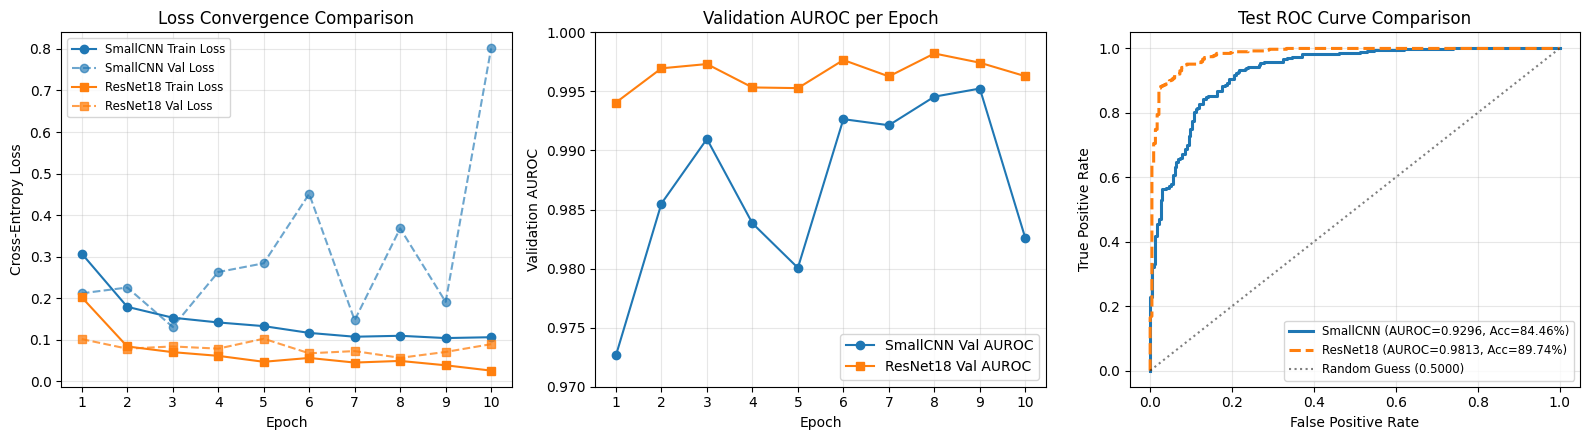

In [8]:
# Part C — 從零訓練 (SmallCNN) vs 遷移學習 (Pretrained ResNet18)
from torchvision import models

# =========================================================
# Step 1. 建立預訓練 ResNet18 遷移學習模型
# =========================================================
# 採用做法 (i)：將單通道 28x28 灰階胸片 repeat 成 3 通道並雙線性插值至 64x64，
# 替換最後一層 fc 為 Linear(512, 2)，進行整網微調 (fine-tuning)
class ResNet18Transfer(nn.Module):
    def __init__(self, n_cls=2, pretrained=True):
        super().__init__()
        try:
            weights = models.ResNet18_Weights.DEFAULT if pretrained else None
            self.backbone = models.resnet18(weights=weights)
        except Exception:
            self.backbone = models.resnet18(weights=None)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, n_cls)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x3 = x.repeat(1, 3, 1, 1)
        x64 = F.interpolate(x3, size=(64, 64), mode='bilinear', align_corners=False)
        x_norm = (x64 - self.mean) / self.std
        return self.backbone(x_norm)

resnet_model = ResNet18Transfer(n_cls=2, pretrained=True).to(dev)
opt_res = torch.optim.Adam(resnet_model.parameters(), lr=4e-4)
crit_res = nn.CrossEntropyLoss()

# =========================================================
# Step 2. 訓練 10 Epochs 並記錄驗證集收斂過程
# =========================================================
hist_c = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_auroc': []}
best_res_loss = float('inf')
best_res_state = None

for epoch in range(1, 11):
    resnet_model.train()
    tr_l_sum, tr_corr, tr_tot = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(dev), yb.to(dev)
        opt_res.zero_grad()
        logits = resnet_model(xb)
        loss = crit_res(logits, yb)
        loss.backward()
        opt_res.step()
        tr_l_sum += loss.item() * len(yb)
        tr_corr += (logits.argmax(dim=1) == yb).sum().item()
        tr_tot += len(yb)

    vl_l, vl_a, vl_auc, _, _ = evaluate_loader(resnet_model, val_loader)
    hist_c['train_loss'].append(tr_l_sum / tr_tot)
    hist_c['val_loss'].append(vl_l)
    hist_c['train_acc'].append(tr_corr / tr_tot)
    hist_c['val_acc'].append(vl_a)
    hist_c['val_auroc'].append(vl_auc)
    if vl_l < best_res_loss:
        best_res_loss = vl_l
        best_res_state = copy.deepcopy(resnet_model.state_dict())

# =========================================================
# Step 3. 測試集量化評估與對照表
# =========================================================
resnet_model.load_state_dict(best_res_state)
_, te_a_c, te_auc_c, te_p_c, _ = evaluate_loader(resnet_model, test_loader)
te_preds_c = (te_p_c >= 0.5).astype(np.int64)
tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_test, te_preds_c).ravel()
prec_c = tp_c / (tp_c + fp_c)
rec_c  = tp_c / (tp_c + fn_c)
spec_c = tn_c / (tn_c + fp_c)
f1_c   = 2 * prec_c * rec_c / (prec_c + rec_c)

df_partc = pd.DataFrame([
    {
        "Model": "SmallCNN (From Scratch)",
        "Params": sum(p.numel() for p in model.parameters()),
        "Epoch 1 Val AUROC": round(history['val_auroc'][0], 4),
        "Best Val AUROC": round(max(history['val_auroc']), 4),
        "Test Accuracy": f"{test_acc*100:.2f}%",
        "Test AUROC": round(my_auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "Specificity": round(spec, 4),
        "F1": round(f1, 4),
    },
    {
        "Model": "ResNet18 (ImageNet Pretrained)",
        "Params": sum(p.numel() for p in resnet_model.parameters()),
        "Epoch 1 Val AUROC": round(hist_c['val_auroc'][0], 4),
        "Best Val AUROC": round(max(hist_c['val_auroc']), 4),
        "Test Accuracy": f"{te_a_c*100:.2f}%",
        "Test AUROC": round(te_auc_c, 4),
        "Precision": round(prec_c, 4),
        "Recall": round(rec_c, 4),
        "Specificity": round(spec_c, 4),
        "F1": round(f1_c, 4),
    }
])
display(df_partc)

# =========================================================
# Step 4. 繪製收斂曲線與測試集 ROC 對照圖
# =========================================================
fpr_c, tpr_c, _ = roc_curve(y_test, te_p_c)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(epochs_arr, history['train_loss'], 'o-', color='#1f77b4', label='SmallCNN Train Loss')
ax[0].plot(epochs_arr, history['val_loss'], 'o--', color='#1f77b4', alpha=0.65, label='SmallCNN Val Loss')
ax[0].plot(epochs_arr, hist_c['train_loss'], 's-', color='#ff7f0e', label='ResNet18 Train Loss')
ax[0].plot(epochs_arr, hist_c['val_loss'], 's--', color='#ff7f0e', alpha=0.75, label='ResNet18 Val Loss')
ax[0].set_title("Loss Convergence Comparison")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-Entropy Loss")
ax[0].set_xticks(epochs_arr); ax[0].grid(True, alpha=0.3); ax[0].legend(fontsize=8.5)

ax[1].plot(epochs_arr, history['val_auroc'], 'o-', color='#1f77b4', label='SmallCNN Val AUROC')
ax[1].plot(epochs_arr, hist_c['val_auroc'], 's-', color='#ff7f0e', label='ResNet18 Val AUROC')
ax[1].set_title("Validation AUROC per Epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Validation AUROC")
ax[1].set_xticks(epochs_arr); ax[1].set_ylim(0.97, 1.00); ax[1].grid(True, alpha=0.3); ax[1].legend()

ax[2].plot(fpr, tpr, color='#1f77b4', lw=2.2, label=f'SmallCNN (AUROC={my_auc:.4f}, Acc={test_acc*100:.2f}%)')
ax[2].plot(fpr_c, tpr_c, color='#ff7f0e', lw=2.2, linestyle='--', label=f'ResNet18 (AUROC={te_auc_c:.4f}, Acc={te_a_c*100:.2f}%)')
ax[2].plot([0, 1], [0, 1], 'k:', alpha=0.5, label='Random Guess (0.5000)')
ax[2].set_title("Test ROC Curve Comparison")
ax[2].set_xlabel("False Positive Rate"); ax[2].set_ylabel("True Positive Rate")
ax[2].grid(True, alpha=0.3); ax[2].legend(loc='lower right', fontsize=8.5)

plt.tight_layout()
plt.show()

## 打包工具庫（必做，HW3 起要 import）
把更新後的 `mymetrics.py`（新增 `auroc`）與 `mymodels.py`（`SmallCNN` 網路定義）存到自己的 Google Drive。

In [9]:
# =========================
# mymetrics.py
# =========================
%%writefile /content/drive/MyDrive/medimg_toolkit/mymetrics.py

import numpy as np
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity


def psnr(img1, img2, data_range=1.0):
    """計算 PSNR"""
    return peak_signal_noise_ratio(
        img1, img2, data_range=data_range
    )


def ssim(img1, img2, data_range=1.0):
    """計算 SSIM"""
    return structural_similarity(
        img1,
        img2,
        data_range=data_range
    )


def auroc(y_true, score):
    """計算二分類 AUROC（依 A5 陽性分數 > 陰性分數的配對比例計算，平手計 0.5）"""
    y_true = np.asarray(y_true).ravel()
    score = np.asarray(score, dtype=np.float64).ravel()

    pos = score[y_true == 1]
    neg = score[y_true == 0]

    if len(pos) == 0 or len(neg) == 0:
        return float("nan")

    diff = pos[:, None] - neg[None, :]
    concordant = np.sum(diff > 0) + 0.5 * np.sum(diff == 0)

    return float(concordant / (len(pos) * len(neg)))

Overwriting /content/drive/MyDrive/medimg_toolkit/mymetrics.py


In [10]:
# =========================
# mymodels.py
# =========================
%%writefile /content/drive/MyDrive/medimg_toolkit/mymodels.py

import torch
import torch.nn as nn


class SmallCNN(nn.Module):
    """輕量級 3 區塊 CNN 分類器（3x Conv-BN-ReLU + GAP + Linear，參數量 23,650 < 1M）"""

    def __init__(self, in_channels=1, n_cls=2):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, n_cls)

    def features(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return x

    def forward(self, x):
        a = self.features(x)
        pooled = self.gap(a).flatten(1)
        return self.fc(pooled)

Overwriting /content/drive/MyDrive/medimg_toolkit/mymodels.py


## Part D — 逆向工程（繳交介面固定）

助教會用**你沒看過的保留測例**呼叫下面兩個函式，所以：

- 函式名稱、參數順序、回傳格式 **不可更動**：D1 回傳 (N,28,28) 的 `np.float32`；D2 回傳 (state_dict, 長度 21 的 loss 陣列)。
- 不要讀你自己另存的檔，也不要用全域變數存推出來的參數，常數請寫死在函式內。例外：D1 可以使用載入格建立的教師模型（`TeacherCNN` 類別與 `cnn_state`），助教評分時會用同名變數、在自己的 REVERSE 路徑下提供。
- 函式要能重複呼叫，不依賴前面 cell 的執行順序。
- 報告要寫推理過程：至少比較兩個假說、附支持的圖或數字、說明哪裡不可辨識。

門檻與檔案格式見 `reverse/manifest.json`。下面的自評格只檢查公開資料，通過不代表保留測例一定過。

In [11]:
# === Part D 資料載入 ===
# Colab：把課程發的 reverse/ 整個資料夾放進自己的 Drive 再掛載，或用 files.upload() 上傳。
from google.colab import drive; drive.mount('/content/drive')
import os, json
import numpy as np

REVERSE = '/content/drive/MyDrive/HW2/reverse'   # ← 改成你的路徑
man = json.load(open(os.path.join(REVERSE, 'manifest.json'), encoding='utf-8'))
def L(name): return np.load(os.path.join(REVERSE, name))
def LL(names): return [np.load(os.path.join(REVERSE, x)) for x in names]
import csv, sys
import torch
sys.path.append(REVERSE)                      # teacher_cnn.py 在 reverse/ 裡

D1_in = np.stack(LL(man['D1']['files']['inputs']))       # (8,28,28)
D1_tg = np.stack(LL(man['D1']['files']['targets']))      # (8,28,28)
D1_labels = L('D1_labels.npy')
cnn_state = torch.load(os.path.join(REVERSE, 'cnn.pt'), map_location='cpu')
from teacher_cnn import TeacherCNN          # 類別名見 teacher_cnn.py

D2_feat = L('D2_features.npy')                # (64,16)
D2_lab = L('D2_labels.npy')                   # (64,)
D2_head_init = torch.load(os.path.join(REVERSE, 'D2_head_init.pt'), map_location='cpu')
D2_head_final = torch.load(os.path.join(REVERSE, 'D2_head_final.pt'), map_location='cpu')
D2_loss = np.array([float(r['loss']) for r in
                    csv.DictReader(open(os.path.join(REVERSE, 'D2_loss.csv'), encoding='utf-8'))])
print('D1', D1_in.shape, '| D2 feat', D2_feat.shape, 'loss pts', len(D2_loss))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
D1 (8, 28, 28) | D2 feat (64, 16) loss pts 21


In [12]:
# === D1 這個 CAM 是怎麼畫出來的 ===
from skimage.metrics import structural_similarity as ssim_fn

def report(rows):
    for i, (txt, ok) in enumerate(rows):
        print(f'[{i}] {txt}  ' + ('PASS' if ok else 'FAIL'))
    print('== ALL PASS ==' if all(ok for _, ok in rows) else '== 尚未達標 ==')

def reproduce_D1(inputs):
    # inputs: np.ndarray (N,28,28) float32 -> np.ndarray (N,28,28) float32
    # 要自己載入 cnn.pt 前向取 16x14x14 特徵圖與 fc 權重；目標類別 / fc bias /
    # 負值處理 / 正規化方式 / 正規化與 resize 的先後，都是你要推的設計選擇
    import numpy as np
    import torch
    import torch.nn.functional as F

    inputs = np.asarray(inputs, dtype=np.float32)
    # 推定配方：固定目標類別 class=1、不加 fc.bias、ReLU 截斷負值、
    # 先在 14x14 除以最大值正規化至 [0,1]，再以 bilinear (align_corners=False) 放大回 28x28
    teacher = TeacherCNN()
    teacher.load_state_dict(cnn_state)
    teacher.eval()

    outs = []
    with torch.no_grad():
        x_t = torch.as_tensor(inputs, dtype=torch.float32).unsqueeze(1)  # (N, 1, 28, 28)
        feats = teacher.features(x_t)                                    # (N, 16, 14, 14)
        w_c = teacher.fc.weight[1]                                       # 固定取第 1 類權重 (16,)

        for i in range(len(inputs)):
            raw = (feats[i] * w_c.view(-1, 1, 1)).sum(dim=0)             # (14, 14)，不含 bias
            cam_14 = F.relu(raw)
            mx = cam_14.max()
            if mx > 0:
                cam_14 = cam_14 / mx
            cam_28 = F.interpolate(
                cam_14.unsqueeze(0).unsqueeze(0),
                size=(28, 28),
                mode='bilinear',
                align_corners=False
            ).squeeze(0).squeeze(0)
            outs.append(cam_28.cpu().numpy().astype(np.float32))

    return np.stack(outs, axis=0).astype(np.float32)

# --- 自評：每張 MAE <= 0.003 且 SSIM >= 0.98 ---
pred = reproduce_D1(D1_in)
rows = []
for p, t in zip(pred, D1_tg):
    m = float(np.abs(t - p).mean()); s = ssim_fn(t, p, data_range=1.0)
    rows.append((f'MAE={m:.5f} SSIM={s:.5f}', m <= 0.003 and s >= 0.98))
report(rows)

[0] MAE=0.00000 SSIM=1.00000  PASS
[1] MAE=0.00000 SSIM=1.00000  PASS
[2] MAE=0.00000 SSIM=1.00000  PASS
[3] MAE=0.00000 SSIM=1.00000  PASS
[4] MAE=0.00000 SSIM=1.00000  PASS
[5] MAE=0.00000 SSIM=1.00000  PASS
[6] MAE=0.00000 SSIM=1.00000  PASS
[7] MAE=0.00000 SSIM=1.00000  PASS
== ALL PASS ==


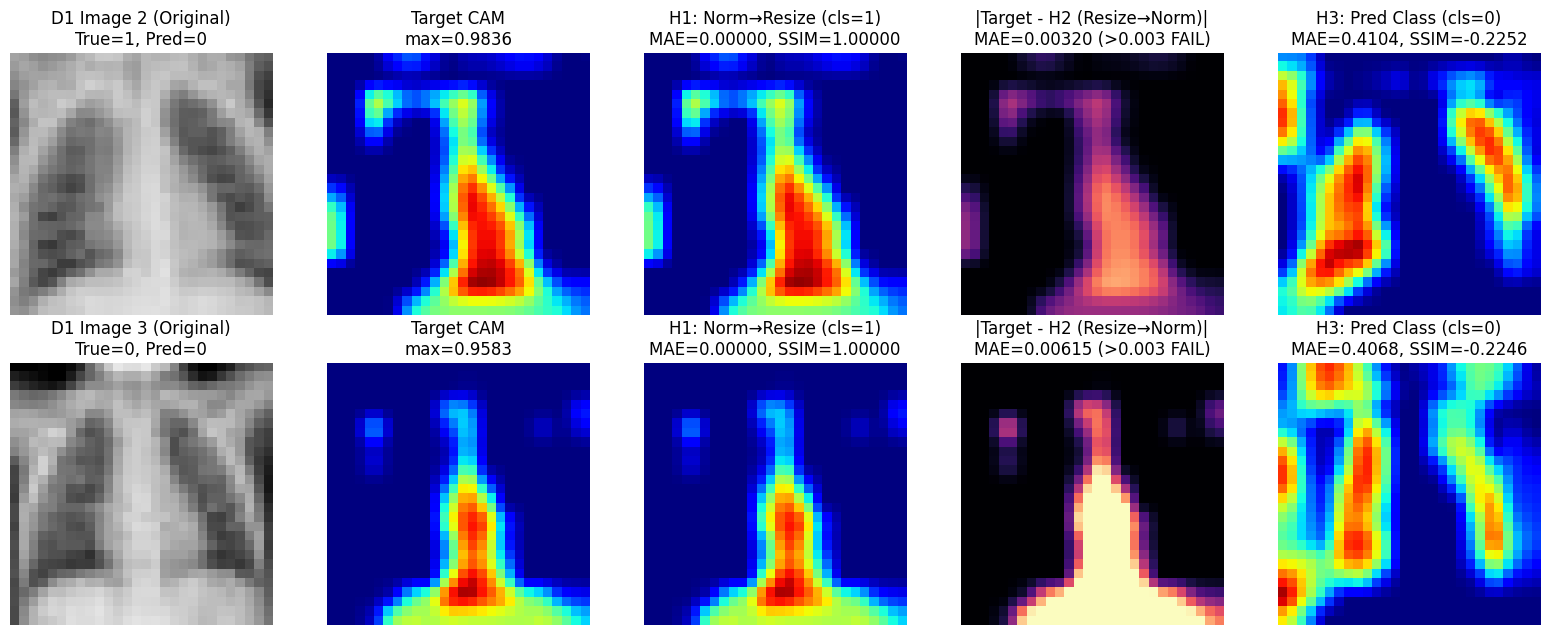

In [13]:
# === D1 假說比較與視覺化 ===
# 假說一 (H1)：固定 class=1，先在 14x14 正規化再 bilinear 放大至 28x28
# 假說二 (H2)：固定 class=1，先 bilinear 放大至 28x28 再正規化
# 假說三 (H3)：改用預測類別 argmax (在 Image 2, 3 上模型預測為 class 0)

teacher = TeacherCNN()
teacher.load_state_dict(cnn_state)
teacher.eval()

with torch.no_grad():
    x_t = torch.as_tensor(D1_in, dtype=torch.float32).unsqueeze(1)
    feats_d1 = teacher.features(x_t)
    preds_d1 = teacher(x_t).argmax(dim=1).numpy()
    w_all = teacher.fc.weight

pred_h1 = reproduce_D1(D1_in)
pred_h2, pred_h3 = [], []

with torch.no_grad():
    for i in range(len(D1_in)):
        # 假說二：先放大至 28x28 再正規化
        raw1 = F.relu((feats_d1[i] * w_all[1].view(-1, 1, 1)).sum(dim=0))
        up28 = F.interpolate(raw1.unsqueeze(0).unsqueeze(0), size=(28, 28), mode='bilinear', align_corners=False).squeeze()
        up28 = up28 / (up28.max() + 1e-12)
        pred_h2.append(up28.numpy().astype(np.float32))

        # 假說三：使用每張圖的預測類別 c_pred
        c_pred = int(preds_d1[i])
        raw_p = F.relu((feats_d1[i] * w_all[c_pred].view(-1, 1, 1)).sum(dim=0))
        raw_p = raw_p / (raw_p.max() + 1e-12)
        up_p = F.interpolate(raw_p.unsqueeze(0).unsqueeze(0), size=(28, 28), mode='bilinear', align_corners=False).squeeze()
        pred_h3.append(up_p.numpy().astype(np.float32))

pred_h2 = np.stack(pred_h2)
pred_h3 = np.stack(pred_h3)

# 繪製被預測為 class 0 的 Image 2 與 Image 3 對照圖
fig, axes = plt.subplots(2, 5, figsize=(16, 6.4))
for row_i, img_idx in enumerate([2, 3]):
    orig, targ = D1_in[img_idx], D1_tg[img_idx]
    h1_im, h2_im, h3_im = pred_h1[img_idx], pred_h2[img_idx], pred_h3[img_idx]

    axes[row_i, 0].imshow(orig, cmap='gray', vmin=0, vmax=1)
    axes[row_i, 0].set_title(f"D1 Image {img_idx} (Original)\nTrue={D1_labels[img_idx]}, Pred={preds_d1[img_idx]}")
    axes[row_i, 0].axis('off')

    axes[row_i, 1].imshow(targ, cmap='jet', vmin=0, vmax=1)
    axes[row_i, 1].set_title(f"Target CAM\nmax={targ.max():.4f}")
    axes[row_i, 1].axis('off')

    m1, s1 = float(np.abs(targ - h1_im).mean()), float(ssim_fn(targ, h1_im, data_range=1.0))
    axes[row_i, 2].imshow(h1_im, cmap='jet', vmin=0, vmax=1)
    axes[row_i, 2].set_title(f"H1: Norm→Resize (cls=1)\nMAE={m1:.5f}, SSIM={s1:.5f}")
    axes[row_i, 2].axis('off')

    m2 = float(np.abs(targ - h2_im).mean())
    axes[row_i, 3].imshow(np.abs(targ - h2_im), cmap='magma', vmin=0, vmax=0.02)
    axes[row_i, 3].set_title(f"|Target - H2 (Resize→Norm)|\nMAE={m2:.5f} (>0.003 FAIL)")
    axes[row_i, 3].axis('off')

    m3, s3 = float(np.abs(targ - h3_im).mean()), float(ssim_fn(targ, h3_im, data_range=1.0))
    axes[row_i, 4].imshow(h3_im, cmap='jet', vmin=0, vmax=1)
    axes[row_i, 4].set_title(f"H3: Pred Class (cls={preds_d1[img_idx]})\nMAE={m3:.4f}, SSIM={s3:.4f}")
    axes[row_i, 4].axis('off')

plt.tight_layout()
plt.show()

In [14]:
# === D2 從權重更新反推訓練配方 ===
def reproduce_D2(features, labels, head_init_state_dict):
    # -> (final_state_dict, losses)；losses 長度 21（含第 0 步）
    # 只訓練 nn.Linear(16,2)，每步都用同一個 full batch。要推的是 loss 是否 class-weighted、
    # optimizer 的 lr / momentum（更新次數已知為 20）
    import torch, torch.nn as nn
    head = nn.Linear(16, 2)
    head.load_state_dict({k: v.clone() for k, v in head_init_state_dict.items()})
    X = torch.as_tensor(features, dtype=torch.float32)
    y = torch.as_tensor(labels, dtype=torch.long)
    losses = []
    # TODO: 依你推出的 loss / optimizer 設定跑 20 步，記錄 21 個 loss
    # 推定配方：CrossEntropyLoss(weight=[1.0, 3.0]) + SGD(lr=0.08, momentum=0.8)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 3.0], dtype=torch.float32))
    optimizer = torch.optim.SGD(head.parameters(), lr=0.08, momentum=0.8)

    for _ in range(20):
        optimizer.zero_grad()
        loss = criterion(head(X), y)
        losses.append(float(loss.item()))
        loss.backward()
        optimizer.step()

    with torch.no_grad():
        losses.append(float(criterion(head(X), y).item()))

    return head.state_dict(), np.array(losses, dtype=np.float64)

# --- 自評：loss 曲線 RMSE <= 1e-4 且參數最大誤差 <= 1e-3 ---
sd, curve = reproduce_D2(D2_feat, D2_lab, D2_head_init)
rmse = float(np.sqrt(np.mean((curve - D2_loss) ** 2))) if len(curve) == len(D2_loss) else float('inf')
perr = max(float((sd[k] - D2_head_final[k]).abs().max()) for k in D2_head_final)
report([(f'curve RMSE={rmse:.2e}', rmse <= 1e-4), (f'max |dparam|={perr:.2e}', perr <= 1e-3)])

[0] curve RMSE=2.23e-08  PASS
[1] max |dparam|=1.19e-07  PASS
== ALL PASS ==


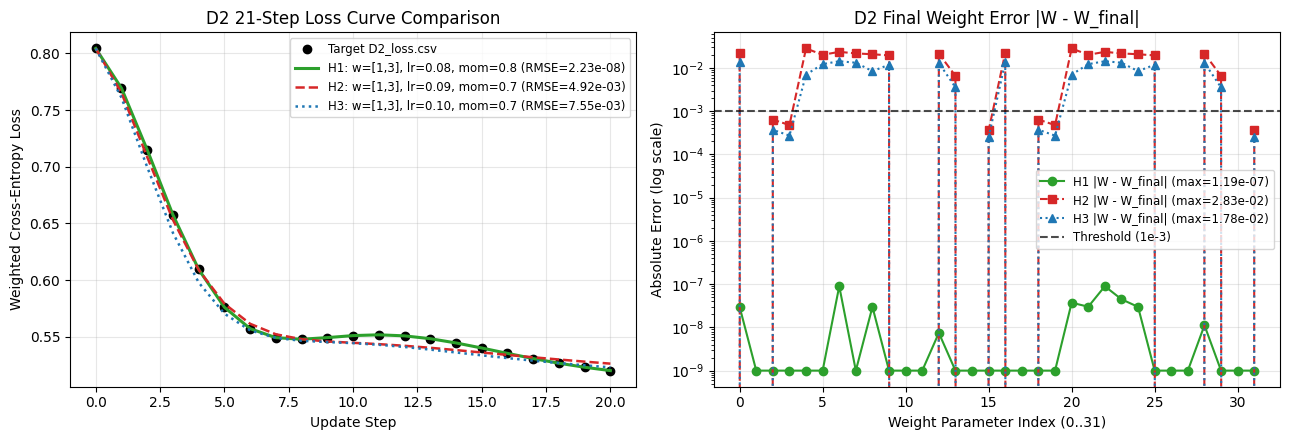

In [15]:
# === D2 假說比較與視覺化 ===
# 比較「Loss 曲線相近但最終權重不同」的三組假說：
#   假說一 (H1)：weight=[1, 3], lr=0.08, momentum=0.8 (正確配方)
#   假說二 (H2)：weight=[1, 3], lr=0.09, momentum=0.7
#   假說三 (H3)：weight=[1, 3], lr=0.10, momentum=0.7

def sim_d2_recipe(w_ratio, lr, mom):
    head = nn.Linear(16, 2)
    head.load_state_dict({k: v.clone() for k, v in D2_head_init.items()})
    X = torch.as_tensor(D2_feat, dtype=torch.float32)
    y = torch.as_tensor(D2_lab, dtype=torch.long)
    crit = nn.CrossEntropyLoss(weight=torch.tensor([1.0, float(w_ratio)], dtype=torch.float32))
    opt = torch.optim.SGD(head.parameters(), lr=lr, momentum=mom)
    losses = []
    for _ in range(20):
        opt.zero_grad()
        loss = crit(head(X), y)
        losses.append(float(loss.item()))
        loss.backward()
        opt.step()
    with torch.no_grad():
        losses.append(float(crit(head(X), y).item()))
    curve_out = np.array(losses, dtype=np.float64)
    sd_out = head.state_dict()
    rmse_out = float(np.sqrt(np.mean((curve_out - D2_loss) ** 2)))
    perr_out = max(float((sd_out[k] - D2_head_final[k]).abs().max()) for k in D2_head_final)
    return curve_out, sd_out, rmse_out, perr_out

c_h1, sd_h1, rmse_h1, perr_h1 = sim_d2_recipe(3, 0.08, 0.8)
c_h2, sd_h2, rmse_h2, perr_h2 = sim_d2_recipe(3, 0.09, 0.7)
c_h3, sd_h3, rmse_h3, perr_h3 = sim_d2_recipe(3, 0.10, 0.7)

steps_arr = np.arange(21)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(steps_arr, D2_loss, 'ko', markersize=6, label='Target D2_loss.csv')
ax[0].plot(steps_arr, c_h1, '-', color='#2ca02c', lw=2.2, label=f'H1: w=[1,3], lr=0.08, mom=0.8 (RMSE={rmse_h1:.2e})')
ax[0].plot(steps_arr, c_h2, '--', color='#d62728', lw=1.8, label=f'H2: w=[1,3], lr=0.09, mom=0.7 (RMSE={rmse_h2:.2e})')
ax[0].plot(steps_arr, c_h3, ':', color='#1f77b4', lw=1.8, label=f'H3: w=[1,3], lr=0.10, mom=0.7 (RMSE={rmse_h3:.2e})')
ax[0].set_title("D2 21-Step Loss Curve Comparison")
ax[0].set_xlabel("Update Step"); ax[0].set_ylabel("Weighted Cross-Entropy Loss")
ax[0].grid(True, alpha=0.3); ax[0].legend(fontsize=8.5)

err_h1 = (sd_h1['weight'] - D2_head_final['weight']).abs().numpy().ravel()
err_h2 = (sd_h2['weight'] - D2_head_final['weight']).abs().numpy().ravel()
err_h3 = (sd_h3['weight'] - D2_head_final['weight']).abs().numpy().ravel()
x_idx = np.arange(len(err_h1))
ax[1].semilogy(x_idx, np.maximum(err_h1, 1e-9), 'o-', color='#2ca02c', label=f'H1 |W - W_final| (max={perr_h1:.2e})')
ax[1].semilogy(x_idx, err_h2, 's--', color='#d62728', label=f'H2 |W - W_final| (max={perr_h2:.2e})')
ax[1].semilogy(x_idx, err_h3, '^:', color='#1f77b4', label=f'H3 |W - W_final| (max={perr_h3:.2e})')
ax[1].axhline(1e-3, color='black', linestyle='--', alpha=0.7, label='Threshold (1e-3)')
ax[1].set_title("D2 Final Weight Error |W - W_final|")
ax[1].set_xlabel("Weight Parameter Index (0..31)"); ax[1].set_ylabel("Absolute Error (log scale)")
ax[1].grid(True, alpha=0.3); ax[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()